# AAPL 2022: Does financial news improve next-day forecasts?

**Controlled proof-of-concept experiment** using your uploaded `AAPL Dataset.csv` and `AAPL_news.csv` (the 3,400-row sentiment export). Compares **LSTM, GRU and Transformer** under **price-only** and **price + FinBERT sentiment/article-count** inputs on exactly the same chronological train/validation/test targets.

**Limitations:** The news dataset is uneven, includes possibly misdated and unrelated articles, and only has substantial 2022 coverage. The exported date is **already delayed 7 calendar days**; we **do not delay it again**. A strictly subsequent trading-session assignment is added as a safeguard, not as proof of date integrity. Models here are exploratory, not actionable trading signals.

## 1. Imports and reproducibility
Run the cells in order. No Hugging Face libraries or FinBERT are needed: your news scores are already calculated.

In [1]:
import copy, random, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:',DEVICE)

Device: cpu


## 2. Upload your two input CSVs
In Colab upload **`AAPL Dataset.csv`** and the **newly processed `AAPL_news.csv`**. If you have `AAPL_news (1).csv` instead, it also works. The notebook will NOT use the old AAME file.

In [2]:
from pathlib import Path
SEARCH=[Path('/content'),Path('.'),Path('/mnt/data')]
def locate(names):
    for directory in SEARCH:
        for name in names:
            f=directory/name
            if f.exists(): return f
    return None
price_path=locate(['AAPL Dataset.csv'])
news_path=locate(['AAPL_news (1).csv','AAPL_news.csv'])
if price_path is None or news_path is None:
    try:
        from google.colab import files
        print('Please upload both Apple price and processed news CSV files:')
        files.upload()
        price_path=locate(['AAPL Dataset.csv'])
        news_path=locate(['AAPL_news (1).csv','AAPL_news.csv'])
    except ImportError: pass
if price_path is None or news_path is None:
    raise FileNotFoundError('Missing AAPL Dataset.csv or AAPL_news.csv; upload both to Colab Files.')
print('Prices:',price_path,'| News:',news_path)
prices=pd.read_csv(price_path)
prices.columns=prices.columns.str.strip()
prices['Date']=pd.to_datetime(prices['Date'],errors='raise').dt.normalize()
base_cols=['Open','High','Low','Close','Volume']
for col in base_cols: prices[col]=pd.to_numeric(prices[col],errors='raise')
prices=prices.sort_values('Date').drop_duplicates('Date').reset_index(drop=True)
assert prices[['Date']+base_cols].notna().all().all()
news=pd.read_csv(news_path)
assert {'published_at','sentiment'}.issubset(news.columns)
news['sentiment']=pd.to_numeric(news['sentiment'],errors='coerce')
news['available_utc']=pd.to_datetime(news['published_at'],utc=True,errors='coerce')
news=news.dropna(subset=['available_utc','sentiment']).copy()
news=news[news.sentiment.between(-1.00001,1.00001)].copy()
# CSV timestamps are often date-only at 00:00 UTC. Use UTC calendar date, NOT
# New York conversion (which would shift midnight timestamps back one day).
news['AvailableDate']=news['available_utc'].dt.tz_localize(None).dt.normalize()
print('Stock rows:',len(prices),'| News records:',len(news))
print('Price range:',prices.Date.min().date(), 'to',prices.Date.max().date())
print('News availability range:',news.AvailableDate.min().date(), 'to',news.AvailableDate.max().date())

Prices: /content/AAPL Dataset.csv | News: /content/AAPL_news (1).csv
Stock rows: 2518 | News records: 3400
Price range: 2013-01-02 to 2022-12-30
News availability range: 2020-03-16 to 2023-01-07


## 3. Assign news to a strictly later trading day
The news `published_at` field contains an **availability proxy**, not necessarily its true publication timestamp. Assign it to the first **strictly later** available session, then aggregate daily mean sentiment and count. A missing-news day is coded as sentiment=0 and count=0; that means *no observed article*, not *neutral coverage*.

In [3]:
sessions=prices[['Date']].sort_values('Date')
assign=pd.merge_asof(
    news.sort_values('AvailableDate'),sessions,
    left_on='AvailableDate',right_on='Date',
    direction='forward',allow_exact_matches=False
).dropna(subset=['Date'])
daily=(assign.groupby('Date',as_index=False)
       .agg(News_Sentiment=('sentiment','mean'),News_Count=('sentiment','size')))
joined=prices.merge(daily,on='Date',how='left')
joined['News_Sentiment']=joined.News_Sentiment.fillna(0.0)
joined['News_Count']=joined.News_Count.fillna(0.0).astype(float)
# Select contiguous calendar period so 10-day sequences aren't artificially joined across gaps.
START='2022-06-01'; END='2022-12-30'; LOOKBACK=10
sample=joined.loc[joined.Date.between(START,END)].copy().reset_index(drop=True)
print('2022 trading sessions:',len(sample),'| news-bearing sessions:',int((sample.News_Count>0).sum()))
print('Articles assigned within window:',int(sample.News_Count.sum()))
print('Coverage proportion:',round((sample.News_Count>0).mean()*100,1),'%')
print('First observed news date:',sample.loc[sample.News_Count>0,'Date'].min())
display(sample[['Date','Close','News_Sentiment','News_Count']].head(12))
if len(sample)<80: raise ValueError('Too few 2022 price rows for this experiment.')

2022 trading sessions: 148 | news-bearing sessions: 140
Articles assigned within window: 2835
Coverage proportion: 94.6 %
First observed news date: 2022-06-13 00:00:00


,Date,Close,News_Sentiment,News_Count
0,2022-06-01,148.710007,0.000000,0.0
1,2022-06-02,151.210007,0.000000,0.0
2,2022-06-03,145.380005,0.000000,0.0
3,2022-06-06,146.139999,0.000000,0.0
4,2022-06-07,148.710007,0.000000,0.0
5,2022-06-08,147.960007,0.000000,0.0
6,2022-06-09,142.639999,0.000000,0.0
7,2022-06-10,137.130005,0.000000,0.0
8,2022-06-13,131.880005,-0.225953,15.0
9,2022-06-14,132.759995,0.118400,24.0


## 4. Common chronological splits and leakage-controlled scaling
Both experiments predict target-day closing price using the **previous ten sessions**; they share **identical target rows**, and scaling is fitted exclusively on training dates. Splits are based on target dates, not independently generated per model.

In [4]:
N=len(sample)
train_end=int(0.70*N); val_end=int(0.85*N)
idx=np.arange(LOOKBACK,N)
split_masks={
 'train':idx<train_end,
 'validation':(idx>=train_end)&(idx<val_end),
 'test':idx>=val_end
}
for k,mask in split_masks.items():
    d=sample.loc[idx[mask],'Date']
    print(f'{k}: {len(d)} targets, {d.min().date()} to {d.max().date()}')
assert all(m.sum()>5 for m in split_masks.values())
TARGET=sample['Close'].to_numpy(dtype=np.float32)
train_target=TARGET[:train_end]
y_mean=float(train_target.mean());y_std=float(train_target.std()) or 1.
y=((TARGET[idx]-y_mean)/y_std).astype('float32')
prev_close=TARGET[idx-1]
target_dates=sample.loc[idx,'Date'].to_numpy()
FEATURE_SETS={
 'Price only':base_cols,
 'Price + news':base_cols+['News_Sentiment','News_Count']
}
def make_windows(feature_cols):
    values=sample[feature_cols].to_numpy(dtype=np.float32)
    mu=values[:train_end].mean(axis=0);sd=values[:train_end].std(axis=0)
    sd=np.where(sd==0,1,sd)
    normalized=(values-mu)/sd
    return np.stack([normalized[t-LOOKBACK:t] for t in idx]).astype('float32')
XSETS={k:make_windows(cols) for k,cols in FEATURE_SETS.items()}
for k,arr in XSETS.items(): print(k,arr.shape)

train: 93 targets, 2022-06-15 to 2022-10-26
validation: 22 targets, 2022-10-27 to 2022-11-28
test: 23 targets, 2022-11-29 to 2022-12-30
Price only (138, 10, 5)
Price + news (138, 10, 7)


## 5. Define GRU, LSTM, Transformer
Architecture and training hyperparameters are held constant between input-feature comparisons (except the necessary input dimension).

In [5]:
class RNNForecast(nn.Module):
    def __init__(self,kind,input_size):
        super().__init__()
        recurrent=nn.GRU if kind=='GRU' else nn.LSTM
        self.rnn=recurrent(input_size,48,batch_first=True)
        self.head=nn.Linear(48,1)
    def forward(self,x):
        out,_=self.rnn(x)
        return self.head(out[:,-1])
class TransformerForecast(nn.Module):
    def __init__(self,input_size):
        super().__init__()
        self.embed=nn.Linear(input_size,48)
        self.position=nn.Parameter(torch.zeros(1,LOOKBACK,48))
        layer=nn.TransformerEncoderLayer(d_model=48,nhead=4,dim_feedforward=96,
                                          dropout=0.1,batch_first=True)
        self.encoder=nn.TransformerEncoder(layer,num_layers=2,enable_nested_tensor=False)
        self.head=nn.Linear(48,1)
    def forward(self,x):
        h=self.embed(x)+self.position[:,:x.shape[1]]
        return self.head(self.encoder(h)[:,-1])
def make_model(name,n_features):
    return (TransformerForecast(n_features) if name=='Transformer'
            else RNNForecast(name,n_features)).to(DEVICE)

## 6. Train six models using validation-based early stopping
The test set is **never inspected for model selection**. The same random seed, targets, and stopping logic are used for both feature sets.

In [6]:
EPOCHS=40;PATIENCE=8; BATCH=32; LR=0.001
def loader(X,mask,shuffle=False):
    ds=TensorDataset(torch.tensor(X[mask]),torch.tensor(y[mask,None]))
    return DataLoader(ds,batch_size=BATCH,shuffle=shuffle)
def train_model(model_name,features):
    random.seed(SEED); np.random.seed(SEED);torch.manual_seed(SEED)
    X=XSETS[features]
    net=make_model(model_name,X.shape[-1])
    optim=torch.optim.Adam(net.parameters(),lr=LR)
    train_l=loader(X,split_masks['train'],True)
    val_l=loader(X,split_masks['validation'])
    best=float('inf');best_state=None;stale=0;hist=[]
    for epoch in range(EPOCHS):
        net.train()
        for xb,yb in train_l:
            xb,yb=xb.to(DEVICE),yb.to(DEVICE)
            optim.zero_grad()
            loss=((net(xb)-yb)**2).mean();loss.backward();optim.step()
        net.eval();losses=[]
        with torch.no_grad():
            for xb,yb in val_l:
                losses.extend(((net(xb.to(DEVICE))-yb.to(DEVICE))**2).flatten().cpu().tolist())
        val_loss=float(np.mean(losses));hist.append(val_loss)
        if val_loss<best-1e-6:
            best=val_loss;best_state=copy.deepcopy(net.state_dict());stale=0
        else:
            stale+=1
            if stale>=PATIENCE:break
    net.load_state_dict(best_state)
    return net,hist
models={};history={}
for feat in FEATURE_SETS:
    for architecture in ('GRU','LSTM','Transformer'):
        key=(architecture,feat)
        models[key],history[key]=train_model(*key)
        print(f'{architecture:11s} | {feat:13s} | epochs {len(history[key]):2d} | best validation loss {min(history[key]):.4f}')

GRU         | Price only    | epochs 26 | best validation loss 0.2544
LSTM        | Price only    | epochs 16 | best validation loss 0.2491
Transformer | Price only    | epochs 38 | best validation loss 0.1923
GRU         | Price + news  | epochs 14 | best validation loss 0.2489
LSTM        | Price + news  | epochs 19 | best validation loss 0.2582
Transformer | Price + news  | epochs  9 | best validation loss 0.1491


## 7. Evaluate on the same held-out dates
Compare MAE and RMSE in raw **dollar** units, R², and directional accuracy. The naive forecast predicts **tomorrow’s close = today’s close**. Since the Apple CSV uses unadjusted Close, stock splits/dividends are not corrected here.

,Model,Features,MAE,RMSE,R2,Directional_Accuracy
0,Naive,Previous close,2.2909,2.9235,0.8176,NaN
1,Transformer,Price only,4.1641,4.8763,0.4925,0.3043
2,GRU,Price only,5.0252,5.9560,0.2429,0.3478
3,LSTM,Price only,6.6668,7.9305,-0.3422,0.3478
4,Transformer,Price + news,6.6717,7.9645,-0.3538,0.4783
5,GRU,Price + news,7.2920,8.3144,-0.4753,0.3043
6,LSTM,Price + news,7.9077,9.2058,-0.8086,0.3478


Features,Price + news,Price only,News minus price-only RMSE
Model,,,
GRU,8.3144,5.9560,2.3583
LSTM,9.2058,7.9305,1.2753
Transformer,7.9645,4.8763,3.0882


Negative RMSE difference means news helped on THIS held-out sample.


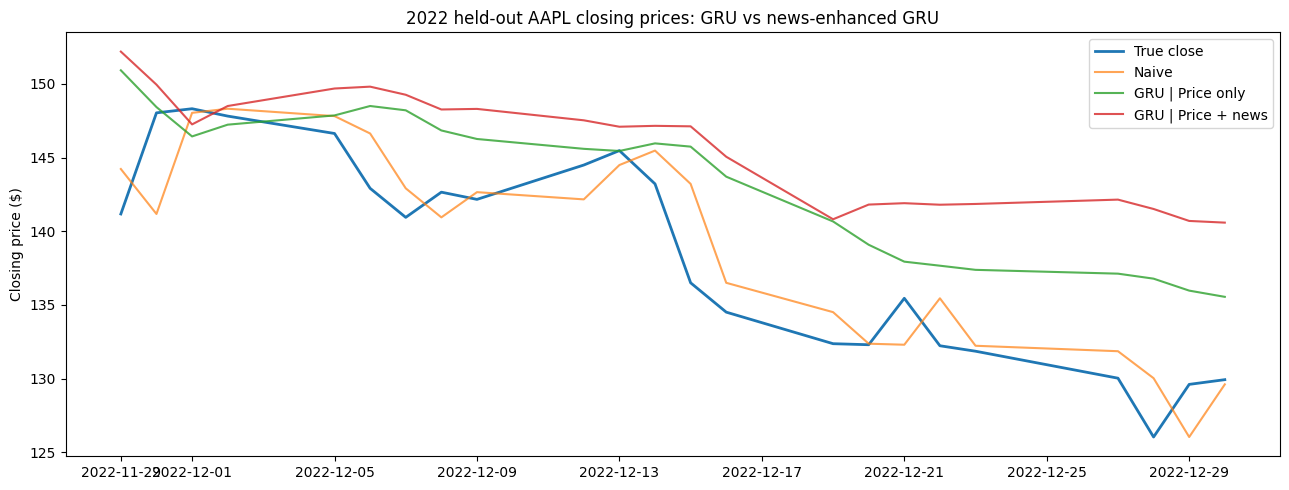

In [7]:
test_mask=split_masks['test'];actual=TARGET[idx[test_mask]];prev=prev_close[test_mask]
dates=target_dates[test_mask]
def predict(net,X,mask):
    net.eval();chunks=[]
    with torch.no_grad():
        for xb,_ in loader(X,mask):
            chunks.append(net(xb.to(DEVICE)).cpu().numpy().ravel())
    return np.concatenate(chunks)*y_std+y_mean
def score(actual,pred,prev):
    return dict(MAE=mean_absolute_error(actual,pred),
                RMSE=np.sqrt(mean_squared_error(actual,pred)),
                R2=r2_score(actual,pred),
                Directional_Accuracy=np.mean(np.sign(pred-prev)==np.sign(actual-prev)))
rows=[];predictions={'Naive':prev}
naive_scores=score(actual,prev,prev)
naive_scores['Directional_Accuracy']=float('nan')  # unchanged-price baseline predicts no direction
rows.append({'Model':'Naive','Features':'Previous close',**naive_scores})
for (name,features),net in models.items():
    pred=predict(net,XSETS[features],test_mask)
    predictions[f'{name} | {features}']=pred
    rows.append({'Model':name,'Features':features,**score(actual,pred,prev)})
results=pd.DataFrame(rows).sort_values('RMSE').reset_index(drop=True)
display(results.round(4))
comparison=(results[results.Model!='Naive'].pivot(index='Model',columns='Features',values='RMSE'))
comparison['News minus price-only RMSE']=comparison['Price + news']-comparison['Price only']
display(comparison.round(4))
print('Negative RMSE difference means news helped on THIS held-out sample.')
plt.figure(figsize=(13,5))
plt.plot(dates,actual,label='True close',linewidth=2)
plt.plot(dates,prev,label='Naive',alpha=.7)
for name in ['GRU | Price only','GRU | Price + news']:
    plt.plot(dates,predictions[name],label=name,alpha=.8)
plt.title('2022 held-out AAPL closing prices: GRU vs news-enhanced GRU')
plt.ylabel('Closing price ($)');plt.legend();plt.tight_layout();plt.show()

## 8. Save results
Save compact results and out-of-sample forecasts. Keep the article-quality caveat when reporting the comparison.

In [8]:
OUTPUT=Path('/content') if Path('/content').exists() else Path('.')
results_path=OUTPUT/'AAPL_2022_model_comparison.csv'
pred_path=OUTPUT/'AAPL_2022_test_predictions.csv'
results.to_csv(results_path,index=False)
pred_table=pd.DataFrame({'Date':dates,'Actual_Close':actual,'Naive_Close':prev})
for name,pred in predictions.items():
    if name!='Naive':pred_table[name]=pred
pred_table.to_csv(pred_path,index=False)
print('Saved:',results_path,'and',pred_path)
try:
    from google.colab import files
    files.download(str(results_path))
    files.download(str(pred_path))
except ImportError: pass

Saved: /content/AAPL_2022_model_comparison.csv and /content/AAPL_2022_test_predictions.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## How to interpret the results

1. Compare **price only vs price + news for the same architecture** on the **same test dates**. Lower RMSE/MAE is better.
2. Check whether the models beat the **previous-close naive baseline**.
3. Treat results as **exploratory only**: few training examples, spotty news coverage, misdated articles, possible irrelevant ticker tags, and no intraday availability verification. A seven-day shift is not a guarantee against leakage.
4. **Do not tune your architecture on the held-out test results.** For credible evidence, collect better timestamped multi-year coverage and repeat over several walk-forward test windows.